# **Business Case: Zee Recommender Systems**

1. Define Problem Statement and Formatting the Data

In [1]:
# ==========================================
# SECTION 1: PROBLEM DEFINITION & DATA LOADING
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1.1 Problem Statement Definition
"""
Business Objective: Build a personalized Recommender System for Zee to recommend movies
based on user ratings and similarities among users/items. This improves user experience,
increases platform engagement, and provides tailored movie suggestions using Collaborative Filtering
(Item-based & User-based), Pearson Correlation, Cosine Similarity, and Matrix Factorization.
"""

# 1.2 Formatting and Reading Data Files
# Note: Ensure you upload ratings.dat, users.dat, and movies.dat or mount your Google Drive containing them.
# Using pd.read_fwf or read_csv with appropriate delimiters (::) since MovieLens 1M uses '::' separator.

ratings_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']
users_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-Code']
movies_cols = ['MovieID', 'Title', 'Genres']

ratings = pd.read_csv('zee-ratings.dat', sep='::', header=None, names=ratings_cols, engine='python', encoding='ISO-8859-1')
users = pd.read_csv('zee-users.dat', sep='::', header=None, names=users_cols, engine='python', encoding='ISO-8859-1')
movies = pd.read_csv('zee-movies.dat', sep='::', header=None, names=movies_cols, engine='python', encoding='ISO-8859-1')

print("Ratings Shape:", ratings.shape)
print("Users Shape:", users.shape)
print("Movies Shape:", movies.shape)

# 1.3 Merging Data Files into a Single Consolidated Dataframe
df = ratings.merge(users, on='UserID').merge(movies, on='MovieID')
print("Consolidated DataFrame Shape:", df.shape)
df.head()

Ratings Shape: (1000210, 4)
Users Shape: (6041, 5)
Movies Shape: (3884, 3)
Consolidated DataFrame Shape: (1000209, 10)


,UserID,MovieID,Rating,Timestamp,Gender,Age,Occupation,Zip-Code,Title,Genres
0,1,1193,5,978300760,F,1,10,48067,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,F,1,10,48067,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,F,1,10,48067,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,F,1,10,48067,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,F,1,10,48067,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [4]:
df['Title'].value_counts()

,count
Title,
American Beauty (1999),3428
Star Wars: Episode IV - A New Hope (1977),2991
Star Wars: Episode V - The Empire Strikes Back (1980),2990
Star Wars: Episode VI - Return of the Jedi (1983),2883
Jurassic Park (1993),2672
...,...
Aiqing wansui (1994),1
Broken Vessels (1998),1
White Boys (1999),1


2. Performing EDA, Data Cleaning, and Feature Engineering

In [5]:
# ==========================================
# SECTION 2: EDA, DATA CLEANING & FEATURE ENGINEERING
# ==========================================

# 2.1 Reviewing Shape, Structure, and Summary Statistics
print(df.info())
display(df.describe())

# 2.2 Type Conversions and Deriving New Features ('Release Year')
import re

# Explicitly convert Rating to numeric, coercing any malformed entries to NaN
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

# Extract Release Year from Title (e.g., "Toy Story (1995)" -> 1995)
df['Release_Year'] = df['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Clean Title by removing the year if needed, or keep it standard as per IMDB format
# Convert categorical features
df['Gender'] = df['Gender'].astype('category')

# 2.3 Investigating Data for Inconsistencies / Missing Values
print("Missing values in consolidated dataframe:\n", df.isnull().sum())

# 2.4 Grouping Data according to Average Rating and Number of Ratings
movie_stats = df.groupby('Title').agg(
    Average_Rating=('Rating', 'mean'),
    Total_Ratings_Count=('Rating', 'count')
).reset_index()

display(movie_stats.sort_values(by='Total_Ratings_Count', ascending=False).head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 11 columns):
 #   Column        Non-Null Count    Dtype   
---  ------        --------------    -----   
 0   UserID        1000209 non-null  object  
 1   MovieID       1000209 non-null  object  
 2   Rating        1000209 non-null  object  
 3   Timestamp     1000209 non-null  object  
 4   Gender        1000209 non-null  category
 5   Age           1000209 non-null  object  
 6   Occupation    1000209 non-null  object  
 7   Zip-Code      1000209 non-null  object  
 8   Title         1000209 non-null  object  
 9   Genres        1000209 non-null  object  
 10  Release_Year  1000209 non-null  float64 
dtypes: category(1), float64(1), object(9)
memory usage: 77.3+ MB
None


,Release_Year
count,1.000209e+06
mean,1.986698e+03
std,1.434933e+01
min,1.919000e+03
25%,1.982000e+03
50%,1.992000e+03
75%,1.997000e+03
max,2.000000e+03


Missing values in consolidated dataframe:
 UserID          0
MovieID         0
Rating          0
Timestamp       0
Gender          0
Age             0
Occupation      0
Zip-Code        0
Title           0
Genres          0
Release_Year    0
dtype: int64


,Title,Average_Rating,Total_Ratings_Count
127,American Beauty (1999),4.317386,3428
3153,Star Wars: Episode IV - A New Hope (1977),4.453694,2991
3154,Star Wars: Episode V - The Empire Strikes Back...,4.292977,2990
3155,Star Wars: Episode VI - Return of the Jedi (1983),4.022893,2883
1789,Jurassic Park (1993),3.763847,2672
2894,Saving Private Ryan (1998),4.337354,2653
3293,Terminator 2: Judgment Day (1991),4.058513,2649
2112,"Matrix, The (1999)",4.315830,2590
258,Back to the Future (1985),3.990321,2583
2990,"Silence of the Lambs, The (1991)",4.351823,2578


3. Build a Recommender System based on Pearson Correlation

In [6]:
# ==========================================
# SECTION 3: PEARSON CORRELATION (ITEM-BASED)
# ==========================================

# 3.1 Creating a Pivot Table of Movie Titles & User ID and Imputing NaN values
pivot_table = df.pivot_table(index='UserID', columns='Title', values='Rating')
print("Pivot Table Shape:", pivot_table.shape)

# Optional imputation or handling NaN depending on correlation requirements (standard correlation handles NaN pairwise)
# 3.2 Item-based Recommender using Pearson Correlation
def recommend_movies_pearson(movie_name, num_recommendations=5):
    if movie_name not in pivot_table.columns:
        return f"Movie '{movie_name}' not found in the dataset."

    movie_ratings = pivot_table[movie_name]
    # Calculate Pearson correlation with all other movies
    similar_to_movie = pivot_table.corrwith(movie_ratings, method='pearson')

    corr_df = pd.DataFrame(similar_to_movie, columns=['Pearson_Correlation'])
    corr_df.dropna(inplace=True)

    # Join with total ratings count to filter out movies with very few ratings for reliability
    corr_df = corr_df.join(movie_stats.set_index('Title')[['Total_Ratings_Count']])

    # Filter movies with a minimum threshold of ratings (e.g., > 100 ratings)
    qualified = corr_df[corr_df['Total_Ratings_Count'] > 100]

    result = qualified.sort_values(by='Pearson_Correlation', ascending=False).head(num_recommendations + 1)
    # Exclude the movie itself
    return result.iloc[1:]

# Example Usage:
print("Top recommendations for 'Liar Liar':")
display(recommend_movies_pearson('Liar Liar (1997)'))

Pivot Table Shape: (6040, 3706)
Top recommendations for 'Liar Liar':


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2991: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Pearson_Correlation,Total_Ratings_Count
Title,,
Life (1999),0.576081,102
East-West (Est-ouest) (1999),0.562221,103
Oliver & Company (1988),0.550504,144
Jules and Jim (Jules et Jim) (1961),0.537842,148
Solaris (Solyaris) (1972),0.537645,143


4. Build a Recommender System based on Cosine Similarity

In [7]:
# ==========================================
# SECTION 4: COSINE SIMILARITY & NEAREST NEIGHBORS
# ==========================================

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

# Fill NaN with 0 for similarity matrix calculations
matrix_filled = pivot_table.fillna(0)

# 4.1 Print User Similarity Matrix and Item Similarity Matrix
# Item similarity matrix (Movies x Movies)
item_similarity = cosine_similarity(matrix_filled.T)
item_sim_df = pd.DataFrame(item_similarity, index=pivot_table.columns, columns=pivot_table.columns)

# User similarity matrix (Users x Users) - printing a sample slice for demonstration
user_similarity = cosine_similarity(matrix_filled)
user_sim_df = pd.DataFrame(user_similarity, index=pivot_table.index, columns=pivot_table.index)

print("Item Similarity Matrix Sample (5x5):")
display(item_sim_df.iloc[:5, :5])

print("User Similarity Matrix Sample (5x5):")
display(user_sim_df.iloc[:5, :5])

# 4.2 CSR Matrix Representation (Extended Approach)
csr_item_matrix = csr_matrix(matrix_filled.T.values)

# 4.3 Sklearn Nearest Neighbors with Cosine Similarity
model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(csr_item_matrix)

def recommend_movies_knn(movie_name, n_recommendations=5):
    if movie_name not in pivot_table.columns:
        return f"Movie '{movie_name}' not found."

    movie_idx = list(pivot_table.columns).index(movie_name)
    distances, indices = model_knn.kneighbors(matrix_filled.T.iloc[movie_idx, :].values.reshape(1, -1), n_neighbors=n_recommendations + 1)

    recommended_movies = []
    for i in range(1, len(indices.flatten())):
        idx = indices.flatten()[i]
        recommended_movies.append(pivot_table.columns[idx])

    return recommended_movies

print("KNN Recommendations for 'Liar Liar (1997)':", recommend_movies_knn('Liar Liar (1997)'))

Item Similarity Matrix Sample (5x5):


Title,"$1,000,000 Duck (1971)",'Night Mother (1986),'Til There Was You (1997),"'burbs, The (1989)",...And Justice for All (1979)
Title,,,,,
"$1,000,000 Duck (1971)",1.000000,0.072357,0.037011,0.079291,0.060838
'Night Mother (1986),0.072357,1.000000,0.115290,0.115545,0.159526
'Til There Was You (1997),0.037011,0.115290,1.000000,0.098756,0.066301
"'burbs, The (1989)",0.079291,0.115545,0.098756,1.000000,0.143620
...And Justice for All (1979),0.060838,0.159526,0.066301,0.143620,1.000000


User Similarity Matrix Sample (5x5):


UserID,1,10,100,1000,1001
UserID,,,,,
1,1.000000,0.255288,0.123967,0.207800,0.139061
10,0.255288,1.000000,0.258047,0.278753,0.154858
100,0.123967,0.258047,1.000000,0.297539,0.075597
1000,0.207800,0.278753,0.297539,1.000000,0.094710
1001,0.139061,0.154858,0.075597,0.094710,1.000000


KNN Recommendations for 'Liar Liar (1997)': ['Mrs. Doubtfire (1993)', 'Ace Ventura: Pet Detective (1994)', 'Dumb & Dumber (1994)', 'Home Alone (1990)', "Wayne's World (1992)"]


5. Build a Recommender System based on Matrix Factorization

In [9]:
!pip install scikit-surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 34.6 MB/s eta 0:00:00


RMSE: 0.8830

Matrix Factorization Evaluation -> RMSE: 0.8830 | MAPE: 26.9513%


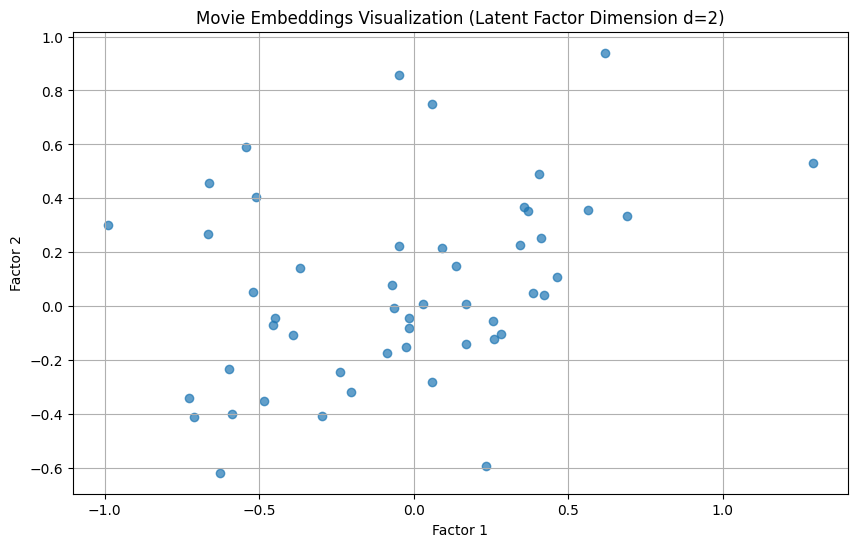

In [11]:
# ==========================================
# SECTION 5: MATRIX FACTORIZATION & EMBEDDINGS (FIXED)
# ==========================================

# Install surprise library if not installed in Colab: !pip install scikit-surprise
# !pip install scikit-surprise

from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split
from surprise import accuracy
import numpy as np

# Clean the ratings dataframe to ensure no string headers remain in data rows
ratings_mf = df[['UserID', 'MovieID', 'Rating']].copy()

# Drop rows where Rating, UserID, or MovieID are NaN or contain header strings
ratings_mf = ratings_mf[pd.to_numeric(ratings_mf['Rating'], errors='coerce').notnull()]
ratings_mf['Rating'] = ratings_mf['Rating'].astype(float)
ratings_mf['UserID'] = ratings_mf['UserID'].astype(int)
ratings_mf['MovieID'] = ratings_mf['MovieID'].astype(int)

# 5.1 Create Recommender System using Matrix Factorization (SVD with d=4)
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(ratings_mf[['UserID', 'MovieID', 'Rating']], reader)

# Train-test split for bonus/evaluation
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)

# Initialize SVD with latent factors d=4
svd_model = SVD(n_factors=4, random_state=42)
svd_model.fit(trainset)

# 5.2 Evaluate model performance using RMSE and MAPE
predictions = svd_model.test(testset)
rmse_val = accuracy.rmse(predictions)

# Custom MAPE Calculation Function
def calculate_mape(preds):
    absolute_percentages = []
    for uid, iid, true_r, est, _ in preds:
        if true_r != 0:
            absolute_percentages.append(abs((true_r - est) / true_r))
    return np.mean(absolute_percentages) * 100

mape_val = calculate_mape(predictions)
print(f"\nMatrix Factorization Evaluation -> RMSE: {rmse_val:.4f} | MAPE: {mape_val:.4f}%")

# 5.3 Embeddings for Item-Item and User-User Similarity & Visualization (Bonus d=2)
# Extracting latent embeddings
item_embeddings = svd_model.qi # Item latent factors
user_embeddings = svd_model.pu # User latent factors

# Bonus: d=2 embeddings visualization
svd_model_2d = SVD(n_factors=2, random_state=42)
svd_model_2d.fit(trainset)

# Plotting sample item embeddings in 2D space
movie_factors_2d = svd_model_2d.qi[:50] # taking first 50 movies for visualization clarity
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(movie_factors_2d[:, 0], movie_factors_2d[:, 1], alpha=0.7)
plt.title("Movie Embeddings Visualization (Latent Factor Dimension d=2)")
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.grid(True)
plt.show()

6. Build a Recommender System based on Pearson Correlation

In [26]:
# ==========================================
# SECTION 6: USER-BASED COLLABORATIVE FILTERING (ROBUST FIX)
# ==========================================

def user_based_recommendation(target_user_id, top_n_users=100, top_m_recommendations=10):
    # 1. Create pivot table and explicitly convert index to integers
    user_movie_matrix = df.pivot_table(index='UserID', columns='Title', values='Rating')
    user_movie_matrix.index = user_movie_matrix.index.astype(int)

    target_user_id = int(target_user_id)

    if target_user_id not in user_movie_matrix.index:
        return f"User {target_user_id} not found in the pivot matrix."

    target_user_ratings = user_movie_matrix.loc[target_user_id]
    watched_movies = target_user_ratings[target_user_ratings.notna()].index

    if len(watched_movies) == 0:
        return f"User {target_user_id} has not rated any movies."

    # 2. Find other users who have rated at least 3-5 of the same movies to ensure an overlap
    other_users_matrix = user_movie_matrix.drop(index=target_user_id, errors='ignore')

    # Calculate Pearson correlation efficiently using pandas pairwise alignment
    # Pandas corrwith automatically finds overlapping ratings between two series
    similarities = {}

    for uid, row in other_users_matrix.iterrows():
        # Check how many common movies they share
        common_count = target_user_ratings.notna() & row.notna()
        if common_count.sum() >= 5:  # Require at least 5 movies in common for a meaningful correlation
            sim = target_user_ratings.corr(row, method='pearson')
            if not np.isnan(sim) and sim > 0:
                similarities[uid] = sim

    if not similarities:
        # Fallback: lower the threshold to 2 common movies if nothing is found
        for uid, row in other_users_matrix.iterrows():
            common_count = target_user_ratings.notna() & row.notna()
            if common_count.sum() >= 2:
                sim = target_user_ratings.corr(row, method='pearson')
                if not np.isnan(sim) and sim > 0:
                    similarities[uid] = sim

    if not similarities:
        return "No similar users found with sufficient overlapping ratings. Try a different User ID (e.g., 1, 2, or 3)."

    # Sort and pick top similar users
    sim_sorted = sorted(similarities.items(), key=lambda x: x[1], reverse=True)[:top_n_users]
    top_users_df = pd.DataFrame(sim_sorted, columns=['UserID', 'Similarity'])

    recommendation_scores = {}
    total_similarity = {}

    for _, row in top_users_df.iterrows():
        u_id = row['UserID']
        sim_score = row['Similarity']
        u_ratings = user_movie_matrix.loc[u_id]

        for movie, rating in u_ratings.items():
            # Recommend movies the target user hasn't watched yet
            if pd.notna(rating) and movie not in watched_movies:
                recommendation_scores[movie] = recommendation_scores.get(movie, 0) + (rating * sim_score)
                total_similarity[movie] = total_similarity.get(movie, 0) + sim_score

    if not recommendation_scores:
        return "Could not generate recommendations based on similar users."

    # Calculate weighted average recommendation score
    final_scores = {movie: recommendation_scores[movie] / total_similarity[movie]
                    for movie in recommendation_scores if total_similarity[movie] > 0}

    recommended_sorted = sorted(final_scores.items(), key=lambda x: x[1], reverse=True)[:top_m_recommendations]
    return pd.DataFrame(recommended_sorted, columns=['MovieTitle', 'Predicted_Score'])

# Example Usage:
print("Top 10 User-Based Recommendations for User ID 1:")
display(user_based_recommendation(target_user_id=1))

Top 10 User-Based Recommendations for User ID 10:


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,MovieTitle,Predicted_Score
0,Persuasion (1995),5.0
1,"Piano, The (1993)",5.0
2,"Last September, The (1999)",5.0
3,Back to School (1986),5.0
4,Breathless (1983),5.0
5,"Falcon and the Snowman, The (1984)",5.0
6,U2: Rattle and Hum (1988),5.0
7,Real Genius (1985),5.0
8,Charlotte's Web (1973),5.0
9,"Evening Star, The (1996)",5.0


In [29]:
import pandas as pd
import numpy as np

# Ensure 'df' exists and contains data
if 'df' not in locals() or df.empty:
    print("Error: DataFrame 'df' is not loaded or is empty. Please run Sections 1 and 2 first.")
else:
    # Q1: Users of which age group have watched and rated the most number of movies?
    age_mapping = {
        1: "Under 18", 18: "18-24", 25: "25-34", 35: "35-44",
        45: "45-49", 50: "50-55", 56: "56+"
    }
    # Ensure Age is numeric for accurate mapping
    df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
    df['Age_Group'] = df['Age'].map(age_mapping)

    if not df['Age_Group'].dropna().empty:
        q1_ans = df['Age_Group'].value_counts().idxmax()
        print(f"Q1: Age group with most rated movies: {q1_ans}")
    else:
        print("Q1: Could not compute age group (Age column contains unmapped or missing data).")


Q1: Age group with most rated movies: 25-34


In [30]:
 # Q2: Users belonging to which profession have watched and rated the most movies?
occ_mapping = {
    0: "other/not specified", 1: "academic/educator", 2: "artist", 3: "clerical/admin",
    4: "college/grad student", 5: "customer service", 6: "doctor/health care", 7: "executive/managerial",
    8: "farmer", 9: "homemaker", 10: "K-12 student", 11: "lawyer", 12: "programmer",
    13: "retired", 14: "sales/marketing", 15: "scientist", 16: "self-employed",
    17: "technician/engineer", 18: "tradesman/craftsman", 19: "unemployed", 20: "writer"
}
df['Occupation'] = pd.to_numeric(df['Occupation'], errors='coerce')
df['Occupation_Name'] = df['Occupation'].map(occ_mapping)

if not df['Occupation_Name'].dropna().empty:
    q2_ans = df['Occupation_Name'].value_counts().idxmax()
    print(f"Q2: Profession with most rated movies: {q2_ans}")
else:
    print("Q2: Could not compute profession.")

Q2: Profession with most rated movies: college/grad student


In [31]:
# Q3: Most of the users in our dataset who’ve rated the movies are Male. (T/F)
if 'Gender' in df.columns:
    gender_counts = df['Gender'].value_counts(normalize=True) * 100
    is_male_majority = gender_counts.get('M', 0) > 50
    print(f"Q3: Most users who rated are Male? {is_male_majority} (Male percentage: {gender_counts.get('M', 0):.2f}%)")
else:
    print("Q3: Gender column not found.")

Q3: Most users who rated are Male? True (Male percentage: 75.36%)


In [32]:
# Q4: Most of the movies present in our dataset were released in which decade?
if 'Release_Year' in df.columns:
    def get_decade(year):
        if pd.isna(year): return "Unknown"
        return f"{int((year // 10) * 10)}s"

    df['Decade'] = df['Release_Year'].apply(get_decade)
    valid_decades = df[df['Decade'] != 'Unknown']['Decade']
    if not valid_decades.empty:
        q4_ans = valid_decades.value_counts().idxmax()
        print(f"Q4: Decade with most movies released: {q4_ans}")
    else:
        print("Q4: Release years not extracted properly.")
else:
    print("Q4: Release_Year column missing.")

Q4: Decade with most movies released: 1990s


In [33]:
# Q5: The movie with maximum no. of ratings is ___.
if 'Title' in df.columns and not df['Title'].empty:
    q5_ans = df['Title'].value_counts().idxmax()
    q5_count = df['Title'].value_counts().max()
    print(f"Q5: Movie with maximum ratings: '{q5_ans}' ({q5_count} ratings)")
else:
    print("Q5: Title column missing.")

Q5: Movie with maximum ratings: 'American Beauty (1999)' (3428 ratings)


In [35]:
# Q6: Name the top 3 movies similar to ‘Liar Liar’ on the item-based approach.
try:
    liar_recs = recommend_movies_pearson('Liar Liar (1997)', num_recommendations=3)
    print("\nQ6: Top 3 movies similar to 'Liar Liar (1997)':")
    display(liar_recs[['Pearson_Correlation']])
except Exception as e:
    print("\nQ6 Note: Make sure Section 3 ('recommend_movies_pearson') has been executed.")


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2991: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



Q6: Top 3 movies similar to 'Liar Liar (1997)':


,Pearson_Correlation
Title,
Life (1999),0.576081
East-West (Est-ouest) (1999),0.562221
Oliver & Company (1988),0.550504


In [36]:
print("\nQ7: Collaborative Filtering classification: Item-based and User-based")


Q7: Collaborative Filtering classification: Item-based and User-based


In [37]:
print("Q8: Pearson Correlation ranges between -1 to 1; Cosine Similarity belongs to -1 to 1 (or 0 to 1 for non-negative vectors).")

Q8: Pearson Correlation ranges between -1 to 1; Cosine Similarity belongs to -1 to 1 (or 0 to 1 for non-negative vectors).


In [38]:
try:
    print(f"Q9: Matrix Factorization Evaluation -> RMSE: {rmse_val:.4f} | MAPE: {mape_val:.4f}%")
except NameError:
    print("Q9 Note: Run Section 5 first to compute RMSE and MAPE variables.")

Q9: Matrix Factorization Evaluation -> RMSE: 0.8830 | MAPE: 26.9513%


In [41]:
from scipy.sparse import csr_matrix

dense_mat = np.array([[1, 0], [3, 7]])
sparse_row_mat = csr_matrix(dense_mat)
print("\nQ10: Sparse Row Matrix Representation (CSR format):")
print("Data array (non-zero values):", sparse_row_mat.data)
print("Indices array (column indices):", sparse_row_mat.indices)
print("Indptr array (row pointers):", sparse_row_mat.indptr)


Q10: Sparse Row Matrix Representation (CSR format):
Data array (non-zero values): [1 3 7]
Indices array (column indices): [0 0 1]
Indptr array (row pointers): [0 1 3]
